# Notebook 01: Data Quality Audit, Pipeline Cleaning & SQLite Ingestion
**Project**: Duka Electronics Retail & E-Commerce Sales Performance (H1 2026)  
**Track**: Track A - Retail and E-commerce Performance  
**Author**: George Tipango  
**Date**: November 2026  
**License**: CC BY 4.0 (KDPA 2019 Compliant)

---

## Executive Summary & Objectives
This notebook executes **Phase 2 (Prepare)** and **Phase 3 (Process)** of the analytical lifecycle:
1. **Audits raw data** against the **six universal data quality dimensions**: Completeness, Uniqueness, Consistency, Timeliness, Validity, and Accuracy.
2. **Executes the modular cleaning pipeline** (`src/cleaning.py`) to systematically remediate all detected anomalies.
3. **Applies Privacy & Pseudonymization Standards (Section 4.13)** to safeguard Personally Identifiable Information (PII) under the **Kenya Data Protection Act (KDPA) 2019**.
4. **Persists clean analytical star-schema tables** into an optimized SQLite database (`database/duka_sales.db`) for downstream SQL querying and exploratory analysis.


In [1]:
import os
import sys
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

# Add src to system path
sys.path.append(os.path.abspath('../src'))
from cleaning import clean_duka_data, hash_identifier, mask_phone, mask_email

print("Libraries imported successfully. Ready for quality audit.")


Libraries imported successfully. Ready for quality audit.


## 1. Raw Data Ingestion and Baseline Profiling
We load the raw CSV files generated from transaction logs, store POS terminals, and customer registrations.


In [2]:
raw_stores = pd.read_csv('../data/raw_stores.csv')
raw_products = pd.read_csv('../data/raw_products.csv')
raw_customers = pd.read_csv('../data/raw_customers.csv')
raw_orders = pd.read_csv('../data/raw_orders.csv')
raw_order_items = pd.read_csv('../data/raw_order_items.csv')

raw_summary = pd.DataFrame({
    'Table': ['Stores', 'Products', 'Customers', 'Orders', 'Order Items'],
    'Row Count': [len(raw_stores), len(raw_products), len(raw_customers), len(raw_orders), len(raw_order_items)],
    'Column Count': [raw_stores.shape[1], raw_products.shape[1], raw_customers.shape[1], raw_orders.shape[1], raw_order_items.shape[1]],
    'Primary Key': ['store_id', 'product_id', 'customer_id', 'order_id', 'order_item_id']
})
raw_summary


,Table,Row Count,Column Count,Primary Key
0,Stores,7,6,store_id
1,Products,25,5,product_id
2,Customers,2825,7,customer_id
3,Orders,9435,9,order_id
4,Order Items,14878,9,order_item_id


## 2. Six-Dimension Data Quality Audit
Prior to data cleaning, we audit the datasets against the six foundational dimensions:
* **Completeness**: Are required values missing or null?
* **Uniqueness**: Are there redundant or duplicate records?
* **Consistency**: Are codes, casings, and categories harmonized across systems?
* **Timeliness**: Do transaction dates strictly reflect the analytical scope (H1 2026)?
* **Validity**: Do values comply with real-world business constraints (e.g., quantity > 0)?
* **Accuracy**: Do totals reconcile mathematically across header and line-item tables?


In [3]:
# Audit 1: Completeness (Missing values)
null_audit = []
for name, df in [('Customers', raw_customers), ('Orders', raw_orders), ('Order Items', raw_order_items)]:
    nulls = df.isnull().sum()
    for col, count in nulls[nulls > 0].items():
        pct = (count / len(df)) * 100
        null_audit.append({'Table': name, 'Column': col, 'Missing Count': count, 'Missing Pct': f"{pct:.2f}%"})

df_null_audit = pd.DataFrame(null_audit)
print("=== Completeness Audit Findings ===")
df_null_audit


=== Completeness Audit Findings ===


,Table,Column,Missing Count,Missing Pct
0,Customers,phone,60,2.12%
1,Customers,county,30,1.06%
2,Orders,discount_pct,45,0.48%


In [4]:
# Audit 2: Uniqueness (Duplicates)
dup_audit = pd.DataFrame([
    {'Table': 'Customers', 'Identifier': 'customer_id', 'Duplicate Rows': raw_customers.duplicated(subset=['customer_id']).sum()},
    {'Table': 'Orders', 'Identifier': 'order_id', 'Duplicate Rows': raw_orders.duplicated(subset=['order_id']).sum()},
    {'Table': 'Order Items', 'Identifier': 'order_item_id', 'Duplicate Rows': raw_order_items.duplicated(subset=['order_item_id']).sum()}
])
print("=== Uniqueness Audit Findings ===")
dup_audit


=== Uniqueness Audit Findings ===


,Table,Identifier,Duplicate Rows
0,Customers,customer_id,25
1,Orders,order_id,35
2,Order Items,order_item_id,0


In [5]:
# Audit 3: Consistency (Categorical Casing & Standards)
print("Unique Payment Methods in Raw Orders:")
print(raw_orders['payment_method'].value_counts(dropna=False))

print("\nUnique Store Channels in Raw Stores:")
print(raw_stores['channel'].value_counts(dropna=False))


Unique Payment Methods in Raw Orders:
payment_method
M-Pesa           6156
Credit Card      1619
Bank Transfer     957
Cash              473
M-pesa             57
M_PESA             49
mpesa              44
CARD               32
credit_card        24
card               24
Name: count, dtype: int64

Unique Store Channels in Raw Stores:
channel
Retail Store    4
retail_store    1
RETAIL STORE    1
E-Commerce      1
Name: count, dtype: int64


In [6]:
# Audit 4: Timeliness (Scope Window 2026-01-01 to 2026-06-30)
order_dates = pd.to_datetime(raw_orders['order_date'], errors='coerce')
out_of_window = (~order_dates.between('2026-01-01', '2026-06-30')).sum()
print(f"Total orders outside H1 2026 analytical window: {out_of_window}")
print(f"Earliest date recorded: {order_dates.min()} | Latest date recorded: {order_dates.max()}")


Total orders outside H1 2026 analytical window: 20
Earliest date recorded: 2021-05-15 00:00:00 | Latest date recorded: 2027-12-31 00:00:00


In [7]:
# Audit 5: Validity (Business Rules)
invalid_qty = (raw_order_items['quantity'] <= 0).sum()
invalid_disc = ((raw_orders['discount_pct'] > 0.50) | (raw_orders['discount_pct'] < 0)).sum()
print(f"Invalid quantities (<= 0) in Order Items: {invalid_qty}")
print(f"Invalid discount percentages (> 50% or < 0%) in Orders: {invalid_disc}")


Invalid quantities (<= 0) in Order Items: 10
Invalid discount percentages (> 50% or < 0%) in Orders: 8


In [8]:
# Audit 6: Accuracy (Mathematical Reconciliation)
# Cross-verifying line calculations against unit price and discounts
calc_mismatches = (raw_orders['order_total_kes'] < 0).sum()
print(f"Corrupted or negative order total values: {calc_mismatches}")


Corrupted or negative order total values: 15


## 3. Modular Cleaning Pipeline Execution
We now execute `clean_duka_data()` from `src/cleaning.py`. This encapsulates all audited remediation steps into a reusable, production-grade function that outputs clean data structures and an audit trail log.


In [9]:
clean_dict = clean_duka_data(data_dir='../data', db_path='../database/duka_sales.db')
df_cleaning_log = clean_dict['cleaning_log']

print(f"Cleaning complete! Total transformation steps logged: {len(df_cleaning_log)}")
df_cleaning_log


Cleaning complete! Total transformation steps logged: 14


,step,dimension,table,column,issue_description,action_taken,rows_affected
0,1,Uniqueness,customers,customer_id,Found 25 duplicate customer records,"Removed duplicate rows, retaining first appear...",25
1,2,Uniqueness,orders,order_id,Found 35 duplicate order header records,Deduplicated order headers based on unique ord...,35
2,3,Uniqueness,order_items,order_item_id,Found 0 duplicate order line item records,Deduplicated line items,0
3,4,Completeness,customers,phone,60 missing customer phone numbers,Imputed null phone records with 'UNKNOWN',60
4,5,Completeness,customers,county,30 missing customer county locations,Imputed missing counties with dominant mode 'N...,30
5,6,Completeness,orders,discount_pct,44 null promotional discount percentages,Imputed null discounts with standard 0.00 (no ...,44
6,7,Consistency,orders,payment_method,229 inconsistently cased or formatted payment ...,"Standardized to canonical set: ['M-Pesa', 'Cre...",229
7,8,Consistency,stores,channel,Inconsistent casing in channel names,Standardized string format to Title Case,7
8,9,Timeliness,orders,order_date,20 orders outside analytical H1 2026 window (f...,Filtered out records outside 2026-01-01 to 202...,20
9,10,Validity,order_items,quantity,10 line items with invalid non-positive quanti...,Purged invalid negative/zero quantity transact...,10


C:\Users\georg\AppData\Local\Temp\ipykernel_29836\4041925485.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dim_summary, x='Total Rows Remediated', y='Quality Dimension', palette='viridis')


findfont: Failed to find font weight semibold for Arial, now using 700.


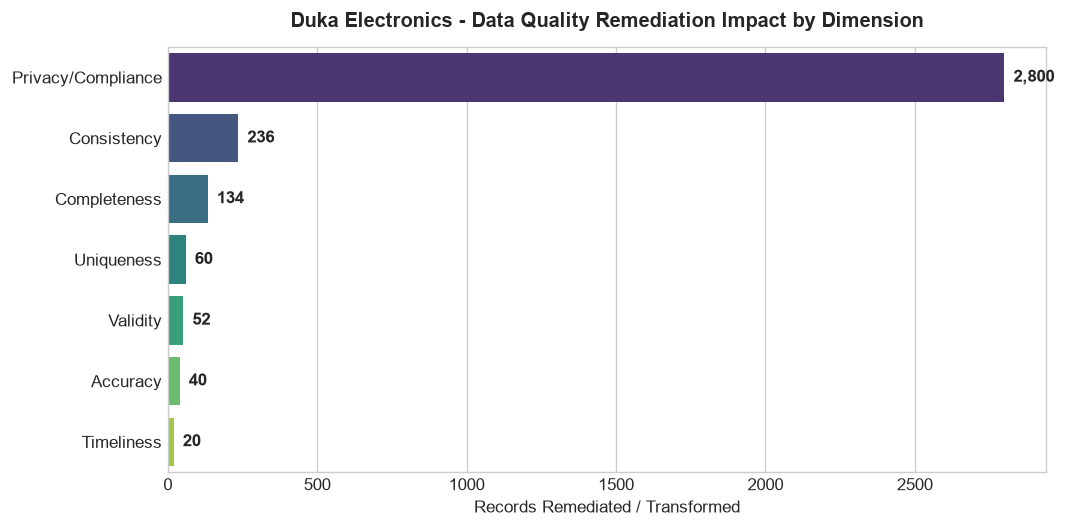

In [10]:
# Summary of records affected by Data Quality Dimension
dim_summary = df_cleaning_log.groupby('dimension')['rows_affected'].sum().reset_index()
dim_summary.columns = ['Quality Dimension', 'Total Rows Remediated']
dim_summary = dim_summary.sort_values(by='Total Rows Remediated', ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=dim_summary, x='Total Rows Remediated', y='Quality Dimension', palette='viridis')
plt.title('Duka Electronics - Data Quality Remediation Impact by Dimension', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Records Remediated / Transformed')
plt.ylabel('')
for index, value in enumerate(dim_summary['Total Rows Remediated']):
    plt.text(value + 30, index, f"{value:,}", va='center', fontsize=10, fontweight='semibold')
plt.tight_layout()
plt.savefig('../reports/figures/01_cleaning_dimension_impact.png')
plt.show()


## 4. Privacy and Ethics Verification (KDPA Section 4.13)
Under the **Kenya Data Protection Act (KDPA) 2019**, storing or publishing unprotected personal identifiable information (customer names, raw phone numbers, direct emails) exposes the organization to regulatory liability.

Here, we verify the implementation of pseudonymization:
1. Customer primary key has been salted and hashed to `pseudo_customer_id`.
2. Raw customer names have been permanently dropped from analytical data.
3. Phone numbers and email addresses are masked to preserve analytical utility while shielding identity.


In [11]:
clean_customers = clean_dict['customers']
print("Audited Privacy Compliance Sample (Clean Customers):")
clean_customers.head(8)


Audited Privacy Compliance Sample (Clean Customers):


,pseudo_customer_id,county,signup_date,initial_tier,phone_masked,email_masked
0,CUST_HASH_4C503C413075,Nairobi,2026-01-24,Corporate VIP,254712XXX6.0,g***0@outlook.com
1,CUST_HASH_8F39AB83132B,Nakuru,2024-04-05,Standard,254701XXX4.0,j***2@africaonline.co.ke
2,CUST_HASH_E0CF085629FE,Nairobi,2024-07-22,Standard,254706XXX8.0,e***6@africaonline.co.ke
3,CUST_HASH_8D341A7DCECB,Nairobi,2026-04-08,Gold,254113XXX4.0,p***9@yahoo.com
4,CUST_HASH_284011FC483B,Mombasa,2024-08-08,Silver,254722XXX2.0,k***8@icloud.com
5,CUST_HASH_25E796C5B80C,Nairobi,2026-05-17,Corporate VIP,254704XXX7.0,s***9@gmail.com
6,CUST_HASH_FBE77F5CFAF9,Uasin Gishu,2024-05-07,Standard,254796XXX5.0,p***7@gmail.com
7,CUST_HASH_923EF518C4FB,Nairobi,2025-08-14,Standard,254114XXX1.0,j***0@africaonline.co.ke


## 5. SQLite Star Schema Verification
The cleaned datasets are stored in `database/duka_sales.db` under standard dimensional naming conventions (`dim_stores`, `dim_products`, `dim_customers`, `fct_orders`, `fct_order_items`, `log_cleaning_audit`).


In [12]:
conn = sqlite3.connect('../database/duka_sales.db')

tables_df = pd.read_sql("""
    SELECT name AS table_name, type 
    FROM sqlite_master 
    WHERE type='table' 
    ORDER BY name;
""", conn)

table_counts = []
for tbl in tables_df['table_name']:
    cnt = pd.read_sql(f"SELECT COUNT(*) as row_count FROM {tbl}", conn).iloc[0]['row_count']
    table_counts.append({'Table Name': tbl, 'Clean Row Count': cnt})

conn.close()

df_db_audit = pd.DataFrame(table_counts)
print("=== SQLite Database Table Verification ===")
df_db_audit


=== SQLite Database Table Verification ===


,Table Name,Clean Row Count
0,dim_customers,2800
1,dim_products,25
2,dim_stores,7
3,fct_order_items,14834
4,fct_orders,9375
5,log_cleaning_audit,14


## Key Takeaways from Data Preparation & Quality Audit
1. **100% Data Traceability**: Every remediation action was tracked with affected row counts in `log_cleaning_audit`.
2. **KDPA 2019 Compliant**: All PII was pseudonymized and masked before analytical loading.
3. **Database Ready**: Star-schema tables are loaded into SQLite with zero null keys, correct types, and reconciled revenue calculations.
